In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.utils import resample
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling  import RandomOverSampler
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from imblearn.ensemble import BalancedRandomForestClassifier

from sklearn.metrics import classification_report ,confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

In [2]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


# EDA

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
print (df.duplicated().sum().sum(),"Duplicate Value Found")

0 Duplicate Value Found


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


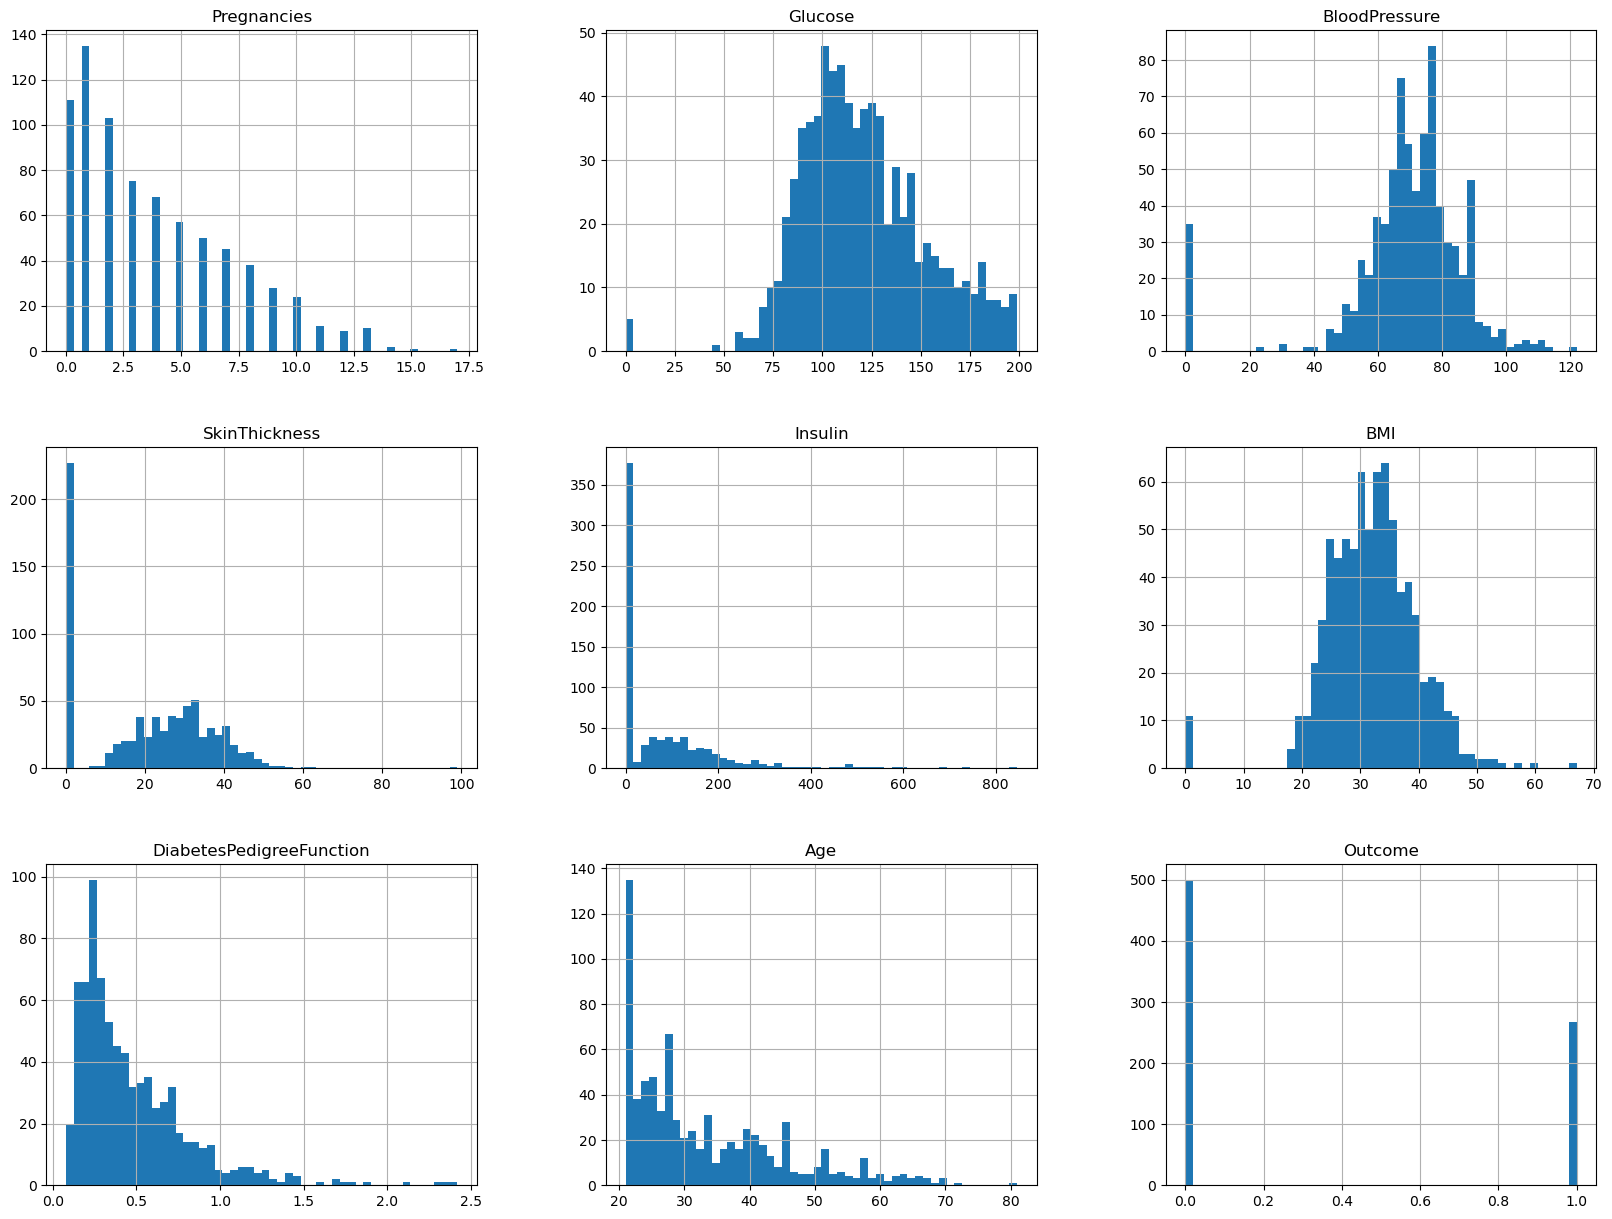

In [6]:
df.hist(bins=50, figsize=(20,15))
plt.show()

In [7]:
target_corr = df.corr()['Outcome'].sort_values(ascending=False) 
target_corr

Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64

<Axes: >

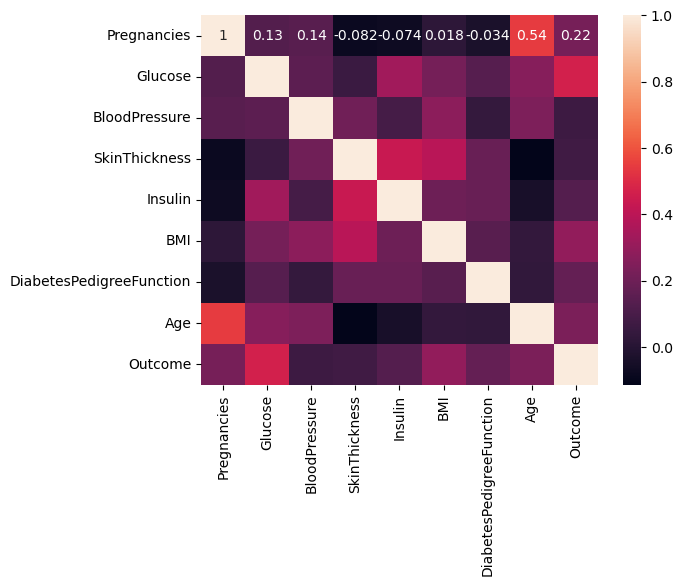

In [8]:
sns.heatmap(df.corr(), annot=True)

In [9]:
df['Outcome'].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

<Axes: ylabel='count'>

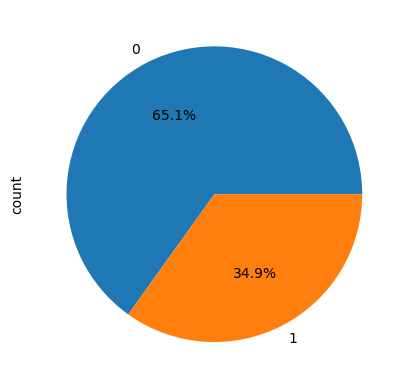

In [10]:
df['Outcome'].value_counts().plot.pie(autopct='%1.1f%%')

# Pre-processing


## fix 0 values

In [11]:
df[['Glucose','BMI', 'BloodPressure', 'SkinThickness', 'Insulin']] = df[['Glucose','BMI',  'BloodPressure','SkinThickness', 'Insulin']].replace(0, np.NaN)
#bmi

df.isna().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

In [12]:
target_corr = df.corr()['Outcome'].sort_values(ascending=False) 
target_corr

Outcome                     1.000000
Glucose                     0.494650
BMI                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64

In [13]:
from sklearn.impute import KNNImputer

# Create the imputer
imputer = KNNImputer(n_neighbors=3)

# Apply imputation and convert back to DataFrame
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

df_imputed.isna().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [14]:
target_corr = df.corr()['Outcome'].sort_values(ascending=False) 
target_corr

Outcome                     1.000000
Glucose                     0.494650
BMI                         0.313680
Insulin                     0.303454
SkinThickness               0.259491
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
BloodPressure               0.170589
Name: Outcome, dtype: float64

In [22]:
X = df_imputed.drop('Outcome',  axis=1)
y = df_imputed['Outcome']

In [23]:
smT = SMOTETomek(random_state=42)
X_resampled, y_resampled = smT.fit_resample(X,y)

y_resampled.value_counts()

Outcome
1.0    472
0.0    472
Name: count, dtype: int64

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled , test_size=0.2, random_state=42)

In [25]:
norm = RobustScaler()
X_train_res_scaled = norm.fit_transform(X_train)
X_test_res_scaled =norm.transform(X_test)

In [27]:
model=RandomForestClassifier(class_weight='balanced')
model.fit(X_train_res_scaled, y_train)

y_pred = model.predict(X_test_res_scaled)


In [28]:
def print_metrics(y_test, y_pred):
  print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.3}")
  print(f"Recall Score: {recall_score(y_test, y_pred):.3}")
  print(f"Precision Score: {precision_score(y_test, y_pred):.3}")
  print(f"F1 Score: {f1_score(y_test, y_pred):.3}")
  print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred),'\n')

print("Original Data Metrics:\n")
print_metrics(y_test, y_pred)


Original Data Metrics:

Accuracy Score: 0.831
Recall Score: 0.905
Precision Score: 0.789
F1 Score: 0.843

Confusion Matrix:
 [[71 23]
 [ 9 86]] 

